# Input-visit coverage: sky map and per-band visit counts for a collection

Reads the general visit-info table (`visit_table`, or an equivalent) from an input Butler
collection and shows **where on the sky** those visits are and **how many there are per band**,
using the real DECam focal-plane geometry (the 62 science CCDs of
`lsst.obs.decam.DarkEnergyCamera`) rather than just the pointing centres. Handy for checking
what a template or search run will actually have to work with before launching it.

For every band it produces:

* a **sky map** of the number of input visits overlapping each point (a HEALPix depth map built
  by projecting every CCD of every visit onto the sky);
* a **bar chart** of the number of input visits per band, and a **histogram** of the sky area
  covered at each depth (1 visit, 2 visits, ...);
* the **distribution of the median PSF FWHM** of the input visits (one value per visit: the median
  over its CCDs of the `preliminary_visit_summary` PSF width), as histograms and box plots;
* a summary table (`visits_per_band.csv`).

Visit information is looked up in this order, and the notebook prints which one it used:

1. a visit table dataset (`visit_table`, `visitTable`, `preliminary_visit_table`), which gives the
   boresight `ra`, `dec` and `skyRotation` per visit;
2. `preliminary_visit_summary` (the boresight and rotation are read from each visit's `VisitInfo`);
3. the `exposure` dimension records of the visits that have `raw` datasets in the collection
   (`tracking_ra`, `tracking_dec`, `sky_angle`), which works on e.g. `DECam/raw/all`.

Visits can be excluded by `day_obs` range (`EXCLUDE_DAY_OBS_RANGES`), e.g. to drop the DESGW
search visits and see only the archival visits available as template inputs.

Owner: **Sean MacBride** [@seanmacb](https://github.com/seanmacb/)

Last Verified to Run: **2026-10-15**, against `DECam/search/S250830bp` on `lsst-scipipe-13.1.0`.

Kernel: use the `lsst_stack` kernel ("LSST Science Pipelines"). The DESGW fork of `obs_decam`
should be set up (`setup -j -r $OBSDECAM`, after `setup lsst_distrib`) so the camera and
filter definitions match the repo.

## Parameters

In [18]:
REPO = "/shares/soares-santos.physik.uzh/ButlerProjects/desgw_postgres"

# Input collection whose visits should be mapped, e.g. "DECam/search/<event>",
# "DECam/templates/<event>" or "DECam/raw/all". Chained collections are fine.
INPUT_COLLECTION = "DECam/search/S250830bp"
INSTRUMENT = "DECam"

# Dataset types tried (in order) for the general visit-info table. Names differ between stack
# versions, and the first one found in INPUT_COLLECTION is used.
VISIT_TABLE_CANDIDATES = ["visit_table", "visitTable", "preliminary_visit_table"]
# Fallback when none of those is in the collection (one ExposureCatalog per visit).
VISIT_SUMMARY_DATASET_TYPE = "preliminary_visit_summary"
# Last resort: visits that have this dataset type in the collection.
RAW_DATASET_TYPE = "raw"

# Restrict to some bands, e.g. ["g", "r"]. None uses every band present.
BANDS = None

# Exclude visits observed within these day_obs ranges (YYYYMMDD, inclusive on both ends), e.g. to
# drop the DESGW search visits and keep only the template-eligible archival ones:
#   EXCLUDE_DAY_OBS_RANGES = [(20250830, 20251130)]
# Use None for an open end, e.g. (20250830, None) excludes everything from that night onwards.
# Several ranges can be listed. An empty list excludes nothing.
EXCLUDE_DAY_OBS_RANGES = []

# Cap on the number of visits used, handy for a quick smoke test. None uses all of them.
MAX_VISITS = None

# Bin width [arcsec] of the PSF FWHM histogram.
FWHM_BIN_WIDTH = 0.1

# HEALPix resolution of the depth map. A DECam CCD is ~0.07 x 0.15 deg, so nside=4096
# (~0.014 deg pixels, ~50 pixels per CCD) resolves it well. Lower it for very large footprints.
NSIDE = 4096

# Sky orientation of the camera model: x -> -x, then rotate by ROTATION_SIGN * skyRotation.
# This was calibrated against the per-detector corners in preliminary_visit_summary; the sanity
# check below compares the model with the registry's visit_detector_region, so a wrong value shows.
FLIP_X = True
ROTATION_SIGN = -1

# Tolerance for the geometry sanity check (arcsec, median detector-centre offset)
GEOMETRY_TOLERANCE_ARCSEC = 60.0

OUTPUT_DIR = "."  # where the PNGs and CSV are written

## Connect to the butler and load the visit table

Tables are read from the dataset types above; the table is collection-wide (one row per visit),
so each visit appears once even if the collection chains several runs.

In [19]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import healpy as hp

from lsst import sphgeom
from lsst.daf.butler import Butler

butler = Butler(REPO, collections=[INPUT_COLLECTION])
registry = butler.registry

print(f"Repo: {REPO}")
print(f"Input collection: {INPUT_COLLECTION}")


def _dataset_type_exists(name):
    try:
        registry.getDatasetType(name)
        return True
    except Exception:
        return False


def _first_col(df, names):
    """Return the first of ``names`` present in ``df``, else None."""
    return next((n for n in names if n in df.columns), None)


def load_from_visit_table():
    """(visit, band, ra, dec, rot, expTime) from the first table dataset type with datasets."""
    for name in VISIT_TABLE_CANDIDATES:
        if not _dataset_type_exists(name):
            continue
        refs = list(registry.queryDatasets(name, collections=[INPUT_COLLECTION], findFirst=True))
        if not refs:
            continue
        frames = []
        for ref in refs:
            tbl = butler.get(ref)
            df = tbl.to_pandas() if hasattr(tbl, "to_pandas") else pd.DataFrame(tbl)
            if _first_col(df, ["visit", "visitId"]) is None:
                df = df.reset_index()  # older DataFrame tables index by visitId
            frames.append(df)
        df = pd.concat(frames, ignore_index=True)
        out = pd.DataFrame({
            "visit": df[_first_col(df, ["visit", "visitId"])].astype(int),
            "band": df[_first_col(df, ["band"])] if "band" in df else None,
            "ra": df["ra"],
            "dec": df[_first_col(df, ["dec", "decl"])],
            "rot": df["skyRotation"],
            "expTime": df["expTime"] if "expTime" in df else np.nan,
        })
        return out, f"visit table dataset `{name}`"
    return None, None


def load_from_visit_summary():
    """Same columns, from the VisitInfo of each preliminary_visit_summary."""
    if not _dataset_type_exists(VISIT_SUMMARY_DATASET_TYPE):
        return None, None
    refs = list(registry.queryDatasets(VISIT_SUMMARY_DATASET_TYPE, collections=[INPUT_COLLECTION],
                                       findFirst=True))
    if not refs:
        return None, None
    rows = []
    for ref in refs:
        cat = butler.get(ref)
        if len(cat) == 0:
            continue
        vi = cat[0].getVisitInfo()
        rd = vi.getBoresightRaDec()
        rows.append({
            "visit": int(ref.dataId["visit"]), "band": ref.dataId["band"],
            "ra": rd.getRa().asDegrees(), "dec": rd.getDec().asDegrees(),
            "rot": vi.getBoresightRotAngle().asDegrees(), "expTime": vi.getExposureTime(),
        })
    return pd.DataFrame(rows), f"`{VISIT_SUMMARY_DATASET_TYPE}` VisitInfo"


def load_from_exposure_records():
    """Same columns, from the exposure dimension records of the visits with raws."""
    if not _dataset_type_exists(RAW_DATASET_TYPE):
        return None, None
    exposures = sorted({int(d["exposure"]) for d in registry.queryDataIds(
        ["exposure"], datasets=RAW_DATASET_TYPE, collections=[INPUT_COLLECTION],
        instrument=INSTRUMENT)})
    if not exposures:
        return None, None
    band_of = {r.name: r.band for r in registry.queryDimensionRecords("physical_filter",
                                                                      instrument=INSTRUMENT)}
    rows = []
    for rec in registry.queryDimensionRecords("exposure", instrument=INSTRUMENT,
                                              where="exposure IN (exposures)",
                                              bind={"exposures": exposures}):
        if rec.observation_type != "science" or rec.tracking_ra is None:
            continue
        rows.append({
            "visit": int(rec.id), "band": band_of.get(rec.physical_filter),
            "ra": rec.tracking_ra, "dec": rec.tracking_dec,
            "rot": rec.sky_angle, "expTime": rec.exposure_time,
        })
    return pd.DataFrame(rows), f"`{RAW_DATASET_TYPE}` exposure records"


visits, source = None, None
for loader in (load_from_visit_table, load_from_visit_summary, load_from_exposure_records):
    visits, source = loader()
    if visits is not None and len(visits):
        break
if visits is None or not len(visits):
    raise RuntimeError(f"No visit information found in {INPUT_COLLECTION}")

# Fill missing bands from the registry, drop anything without a usable pointing
if visits["band"].isna().any():
    band_of = {r.name: r.band for r in registry.queryDimensionRecords("physical_filter",
                                                                      instrument=INSTRUMENT)}
    vband = {r.id: band_of.get(r.physical_filter)
             for r in registry.queryDimensionRecords("visit", instrument=INSTRUMENT,
                                                     where="visit IN (v)",
                                                     bind={"v": visits["visit"].tolist()})}
    visits["band"] = visits["band"].fillna(visits["visit"].map(vband))
visits = (visits.dropna(subset=["band", "ra", "dec", "rot"])
          .drop_duplicates("visit").sort_values("visit").reset_index(drop=True))
if BANDS is not None:
    visits = visits[visits["band"].isin(BANDS)].reset_index(drop=True)

# day_obs of every visit, from the registry (visit records, falling back to exposure records
# since a visit shares its id with its exposure on DECam)
day_obs_of = {r.id: r.day_obs for r in registry.queryDimensionRecords(
    "visit", instrument=INSTRUMENT, where="visit IN (v)", bind={"v": visits["visit"].tolist()})}
missing = [v for v in visits["visit"] if v not in day_obs_of]
if missing:
    day_obs_of.update({r.id: r.day_obs for r in registry.queryDimensionRecords(
        "exposure", instrument=INSTRUMENT, where="exposure IN (e)", bind={"e": missing})})
visits["day_obs"] = visits["visit"].map(day_obs_of)

excluded = pd.Series(False, index=visits.index)
for start, end in EXCLUDE_DAY_OBS_RANGES:
    excluded |= ((visits["day_obs"] >= (start if start is not None else -np.inf))
                 & (visits["day_obs"] <= (end if end is not None else np.inf)))
if excluded.any():
    print(f"Excluding {excluded.sum()} visits in day_obs ranges {EXCLUDE_DAY_OBS_RANGES}:")
    print(visits[excluded].groupby("band").size().rename("n_excluded").to_string())
visits = visits[~excluded].reset_index(drop=True)
if not len(visits):
    raise RuntimeError("All visits were excluded by EXCLUDE_DAY_OBS_RANGES")
if MAX_VISITS is not None:
    visits = visits.head(MAX_VISITS)

print(f"Visit information from {source}: {len(visits)} visits "
      f"(day_obs {visits['day_obs'].min()} to {visits['day_obs'].max()})")
print(visits.groupby("band").size().rename("n_visits").to_string())
visits.head()

Repo: /shares/soares-santos.physik.uzh/ButlerProjects/desgw_postgres
Input collection: DECam/search/S250830bp
Visit information from `preliminary_visit_summary` VisitInfo: 135 visits (day_obs 20170618 to 20250924)
band
g    33
i    49
r    24
z    29


,visit,band,ra,dec,rot,expTime,day_obs
0,654601,g,333.669837,-78.439475,90.0,90.0,20170618
1,654602,r,333.669629,-78.439336,90.0,90.0,20170618
2,654603,g,320.331082,-78.898169,90.0,90.0,20170618
3,654604,r,320.331036,-78.898087,90.0,90.0,20170618
4,754844,r,331.380882,-78.173947,90.0,30.0,20180712


## DECam camera model

The camera model gives each of the 62 science CCDs as a polygon of field-angle offsets from the
boresight. Per visit those polygons are rotated by the visit's sky rotation and projected onto the
sky with an inverse gnomonic (tangent-plane) projection about the boresight `ra`, `dec`.

In [20]:
from lsst.afw.cameraGeom import FOCAL_PLANE, FIELD_ANGLE, DetectorType
from lsst.obs.decam import DarkEnergyCamera

camera = DarkEnergyCamera().getCamera()
focal_to_field = camera.getTransformMap().getTransform(FOCAL_PLANE, FIELD_ANGLE)

# {detector id: (4, 2) array of field-angle corners [radians]}
FIELD_CORNERS = {}
for det in camera:
    if det.getType() != DetectorType.SCIENCE:
        continue
    pts = focal_to_field.applyForward(det.getCorners(FOCAL_PLANE))
    FIELD_CORNERS[det.getId()] = np.array([[p.getX(), p.getY()] for p in pts])
DETECTOR_IDS = sorted(FIELD_CORNERS)
FIELD_CORNERS_ARR = np.array([FIELD_CORNERS[d] for d in DETECTOR_IDS])  # (ndet, 4, 2)
print(f"{len(DETECTOR_IDS)} science detectors; max field angle "
      f"{np.degrees(np.abs(FIELD_CORNERS_ARR).max()):.2f} deg")


def tangent_to_radec(xi, eta, ra0, dec0):
    """Inverse gnomonic projection. xi (east) and eta (north) are tangent-plane coordinates
    (dimensionless, ~radians); ra0, dec0 in degrees. Returns ra, dec in degrees."""
    d0 = np.radians(dec0)
    rho = np.hypot(xi, eta)
    c = np.arctan(rho)
    with np.errstate(invalid="ignore", divide="ignore"):
        sin_term = np.where(rho > 0, eta * np.sin(c) * np.cos(d0) / rho, 0.0)
    dec = np.arcsin(np.cos(c) * np.sin(d0) + sin_term)
    ra = np.radians(ra0) + np.arctan2(xi * np.sin(c),
                                      rho * np.cos(d0) * np.cos(c) - eta * np.sin(d0) * np.sin(c))
    return np.degrees(ra) % 360.0, np.degrees(dec)


def radec_to_tangent(ra, dec, ra0, dec0):
    """Gnomonic projection, the inverse of `tangent_to_radec`."""
    ra, dec, ra0, dec0 = map(np.radians, (ra, dec, ra0, dec0))
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(ra - ra0)
    xi = np.cos(dec) * np.sin(ra - ra0) / cosc
    eta = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(ra - ra0)) / cosc
    return xi, eta


def visit_polygons(ra0, dec0, rot_deg):
    """RA, Dec [deg] of every science CCD's corners for one visit; arrays of shape (ndet, 4)."""
    x = FIELD_CORNERS_ARR[..., 0] * (-1.0 if FLIP_X else 1.0)
    y = FIELD_CORNERS_ARR[..., 1]
    t = np.radians(ROTATION_SIGN * rot_deg)
    xr = x * np.cos(t) - y * np.sin(t)
    yr = x * np.sin(t) + y * np.cos(t)
    return tangent_to_radec(np.tan(xr), np.tan(yr), ra0, dec0)

62 science detectors; max field angle 1.08 deg


### Sanity check against the registry

Compares the model's CCD centres for a few visits with the registry's `visit_detector_region`
polygons (an independent geometry from the ingested headers). The registry polygons are padded by
~1 arcmin, so detector *centres* are compared rather than corners. A median offset far above ~1
arcmin (pixels are 0.26") means `FLIP_X` / `ROTATION_SIGN` don't match this camera setup; a wrong
rotation shows up as offsets of degrees.

In [21]:
def _centre(ra, dec):
    """Centre of a small polygon (mean of the corners), robust to the RA wrap."""
    ra0 = ra[0]
    return ra0 + np.mean((ra - ra0 + 180) % 360 - 180), np.mean(dec)


def check_geometry(row):
    recs = list(registry.queryDimensionRecords("visit_detector_region", instrument=INSTRUMENT,
                                               visit=int(row.visit)))
    if not recs:
        return None
    ra_m, dec_m = visit_polygons(row.ra, row.dec, row.rot)
    offsets = []
    for rec in recs:
        if rec.detector not in FIELD_CORNERS:
            continue
        i = DETECTOR_IDS.index(rec.detector)
        verts = [sphgeom.LonLat(v) for v in rec.region.getVertices()]
        rc, dc = _centre(np.array([v.getLon().asDegrees() for v in verts]),
                         np.array([v.getLat().asDegrees() for v in verts]))
        rm, dm = _centre(ra_m[i], dec_m[i])
        offsets.append(np.hypot((rc - rm) * np.cos(np.radians(dc)), dc - dm) * 3600)
    return np.median(offsets), np.max(offsets), len(offsets)


sample = visits.iloc[np.unique(np.linspace(0, len(visits) - 1, 5).astype(int))]
for row in sample.itertuples():
    res = check_geometry(row)
    if res is None:
        print(f"visit {row.visit}: no visit_detector_region records, skipped")
        continue
    med, mx, n = res
    flag = "OK" if med < GEOMETRY_TOLERANCE_ARCSEC else "MISMATCH - check FLIP_X / ROTATION_SIGN"
    print(f"visit {row.visit} ({row.band}): {n} detectors, centre offset median {med:.1f}\" "
          f"max {mx:.1f}\"  {flag}")

visit 654601 (g): 62 detectors, centre offset median 0.9" max 1.4"  OK
visit 884546 (g): 62 detectors, centre offset median 0.9" max 1.3"  OK
visit 1236495 (z): 62 detectors, centre offset median 0.9" max 1.4"  OK
visit 1413970 (g): 62 detectors, centre offset median 0.9" max 1.3"  OK
visit 1419922 (z): 62 detectors, centre offset median 0.9" max 1.3"  OK


## Depth maps

Each CCD polygon is rasterised onto a HEALPix grid. A visit counts at most once per pixel, so the
value of a pixel is the number of distinct visits covering it.

In [22]:
pixel_area_deg2 = hp.nside2pixarea(NSIDE, degrees=True)
bands = sorted(visits["band"].unique(), key=lambda b: "ugrizy".find(b) if b in "ugrizy" else 99)

depth = {}  # band -> (sorted pixel ids, number of visits covering each)
for band in bands:
    chunks = []
    sub = visits[visits["band"] == band]
    for n, row in enumerate(sub.itertuples(), 1):
        ra_p, dec_p = visit_polygons(row.ra, row.dec, row.rot)
        pix = [hp.query_polygon(NSIDE, hp.ang2vec(ra_p[i], dec_p[i], lonlat=True))
               for i in range(len(DETECTOR_IDS))]
        chunks.append(np.unique(np.concatenate(pix)))
        if n % 100 == 0:
            print(f"  {band}: {n}/{len(sub)} visits")
    depth[band] = np.unique(np.concatenate(chunks), return_counts=True)
    pix, cnt = depth[band]
    print(f"{band}: {len(sub)} visits cover {len(pix) * pixel_area_deg2:.1f} deg^2, "
          f"max depth {cnt.max()}")

g: 33 visits cover 18.4 deg^2, max depth 18
r: 24 visits cover 17.2 deg^2, max depth 18
i: 49 visits cover 17.4 deg^2, max depth 33
z: 29 visits cover 17.2 deg^2, max depth 21


## Sky map

One panel per band, all on the same colour scale. Axes are RA and Dec, drawn on a tangent plane
about the centre of the footprint (RA increases to the left); crosses mark the boresight of every
visit.

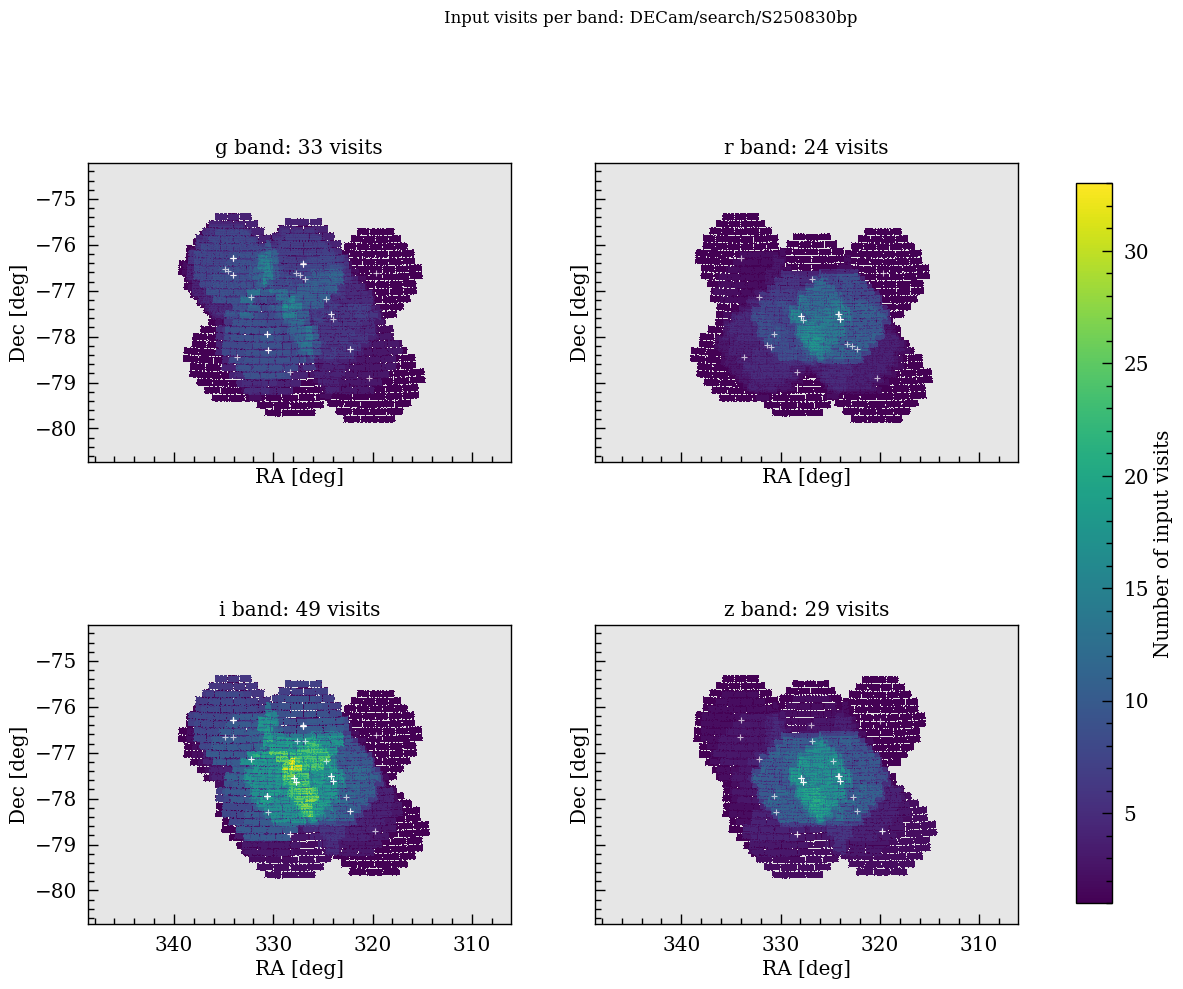

In [23]:
all_pix = np.concatenate([depth[b][0] for b in bands])
lon, lat = hp.pix2ang(NSIDE, np.unique(all_pix), lonlat=True)
ctr = np.mean(hp.ang2vec(lon, lat, lonlat=True), axis=0)
ra0, dec0 = (float(np.ravel(v)[0]) for v in hp.vec2ang(ctr, lonlat=True))
ra0 = ra0 % 360
xi, eta = radec_to_tangent(lon, lat, ra0, dec0)
pad = 0.01 + 0.03 * max(np.ptp(xi), np.ptp(eta))
xlim, ylim = (xi.min() - pad, xi.max() + pad), (eta.min() - pad, eta.max() + pad)

# Regular tangent-plane grid, capped at ~700 cells on the long side
step = max(np.radians(hp.nside2resol(NSIDE, arcmin=True) / 60.0),
           max(np.ptp(xlim), np.ptp(ylim)) / 700.0)
gx = np.arange(xlim[0], xlim[1], step)
gy = np.arange(ylim[0], ylim[1], step)
GX, GY = np.meshgrid(gx, gy)
GRA, GDEC = tangent_to_radec(GX, GY, ra0, dec0)
GPIX = hp.ang2pix(NSIDE, GRA, GDEC, lonlat=True)
plot_ra = ra0 + ((GRA - ra0 + 180) % 360 - 180)  # keep RA continuous across 0/360


def depth_grid(band):
    pix, cnt = depth[band]
    idx = np.clip(np.searchsorted(pix, GPIX), 0, len(pix) - 1)
    return np.where(pix[idx] == GPIX, cnt[idx], np.nan).astype(float)


vmax = max(depth[b][1].max() for b in bands)
ncols = min(len(bands), 2)
nrows = int(np.ceil(len(bands) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7.5 * ncols, 5.5 * nrows), squeeze=False,
                         sharex=True, sharey=True)
for ax, band in zip(axes.ravel(), bands):
    mesh = ax.pcolormesh(plot_ra, GDEC, depth_grid(band), cmap="viridis", vmin=1, vmax=vmax,
                         shading="auto", rasterized=True)
    sub = visits[visits["band"] == band]
    ax.plot(ra0 + ((sub["ra"] - ra0 + 180) % 360 - 180), sub["dec"], "+", color="w", ms=4, mew=0.8,
            alpha=0.7)
    ax.set_title(f"{band} band: {len(sub)} visits")
    ax.set_aspect(1.0 / np.cos(np.radians(dec0)))
    ax.set_xlabel("RA [deg]")
    ax.set_ylabel("Dec [deg]")
    ax.set_facecolor("0.9")
for ax in axes.ravel()[len(bands):]:
    ax.axis("off")
axes[0, 0].invert_xaxis()  # axes are shared, so this flips every panel
fig.colorbar(mesh, ax=axes.ravel().tolist(), label="Number of input visits", shrink=0.85)
fig.suptitle(f"Input visits per band: {INPUT_COLLECTION}")
os.makedirs(OUTPUT_DIR, exist_ok=True)
fig.savefig(os.path.join(OUTPUT_DIR, "visit_coverage_map.png"), dpi=150, bbox_inches="tight")
plt.show()

## Visits per band and depth distribution

Left: number of input visits per band. Right: how much sky is covered by exactly *N* visits in
each band, i.e. the distribution of the map above.

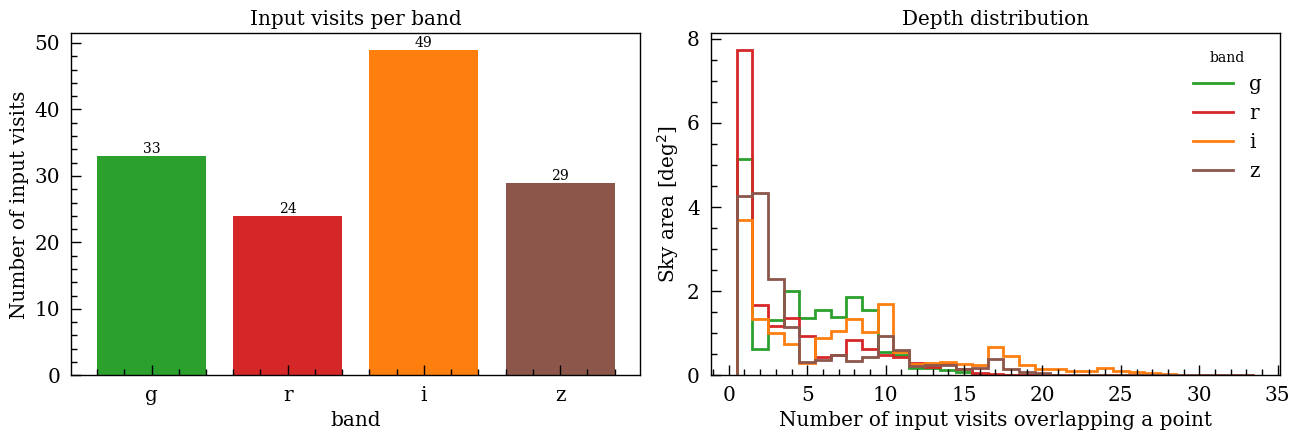

In [24]:
BAND_COLORS = {"u": "tab:purple", "g": "tab:green", "r": "tab:red", "i": "tab:orange",
               "z": "tab:brown", "y": "tab:gray", "Y": "tab:gray"}
colors = {b: BAND_COLORS.get(b, "tab:blue") for b in bands}
n_visits = visits.groupby("band").size().reindex(bands)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
bars = ax1.bar(bands, n_visits.values, color=[colors[b] for b in bands])
ax1.bar_label(bars)
ax1.set_xlabel("band")
ax1.set_ylabel("Number of input visits")
ax1.set_title("Input visits per band")

edges = np.arange(1, vmax + 2) - 0.5
for band in bands:
    pix, cnt = depth[band]
    area = np.bincount(cnt, minlength=vmax + 1)[1:] * pixel_area_deg2
    ax2.stairs(area, edges, color=colors[band], lw=2, label=band)
ax2.set_xlabel("Number of input visits overlapping a point")
ax2.set_ylabel("Sky area [deg$^2$]")
ax2.set_title("Depth distribution")
ax2.legend(title="band")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "visit_coverage_hist.png"), dpi=150, bbox_inches="tight")
plt.show()

## PSF FWHM distribution

The visit table has no PSF size, so it is taken from the per-detector `psfSigma` in
`preliminary_visit_summary` (the same dataset type as `VISIT_SUMMARY_DATASET_TYPE`) for the
visits kept above. Each visit gets one number, the **median over its CCDs** of
`FWHM = 2.355 * psfSigma * pixelScale`; CCDs without a valid PSF are ignored. Visits with no
summary in the collection are left out of this section only.

In [25]:
GAUSSIAN_SIGMA_TO_FWHM = 2.3548200450309493  # 2 * sqrt(2 * ln(2))


def median_fwhm_arcsec(cat):
    """Median PSF FWHM [arcsec] over the valid detectors of a visit summary catalog."""
    sigma = np.asarray(cat["psfSigma"], dtype=float)
    scale = np.asarray(cat["pixelScale"], dtype=float)
    fwhm = GAUSSIAN_SIGMA_TO_FWHM * sigma * scale
    fwhm = fwhm[np.isfinite(fwhm) & (sigma > 0)]
    return float(np.median(fwhm)) if len(fwhm) else np.nan


visits["fwhm"] = np.nan
if _dataset_type_exists(VISIT_SUMMARY_DATASET_TYPE):
    fwhm_of = {}
    for ref in registry.queryDatasets(VISIT_SUMMARY_DATASET_TYPE, collections=[INPUT_COLLECTION],
                                      findFirst=True, where="visit IN (v)",
                                      bind={"v": visits["visit"].tolist()}):
        fwhm_of[int(ref.dataId["visit"])] = median_fwhm_arcsec(butler.get(ref))
    visits["fwhm"] = visits["visit"].map(fwhm_of)
n_fwhm = int(visits["fwhm"].notna().sum())
print(f"PSF FWHM available for {n_fwhm} of {len(visits)} visits")

PSF FWHM available for 135 of 135 visits


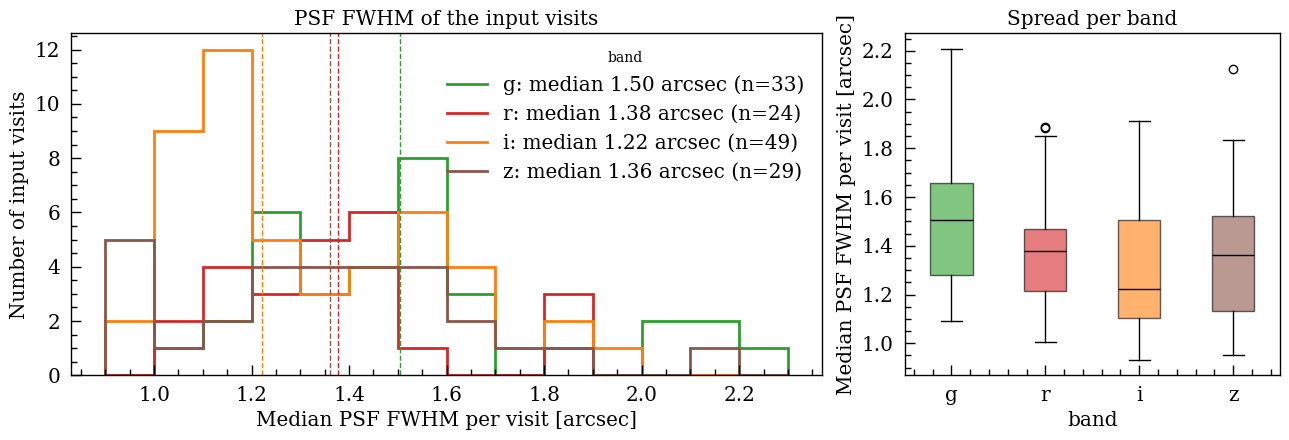

In [26]:
fwhm_bands = [b for b in bands if visits.loc[visits["band"] == b, "fwhm"].notna().any()]
if not fwhm_bands:
    print(f"No {VISIT_SUMMARY_DATASET_TYPE} in {INPUT_COLLECTION}: skipping the PSF FWHM plots")
else:
    lo, hi = visits["fwhm"].min(), visits["fwhm"].max()
    edges = np.arange(np.floor(lo / FWHM_BIN_WIDTH) * FWHM_BIN_WIDTH,
                      hi + FWHM_BIN_WIDTH, FWHM_BIN_WIDTH)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
    data = []
    for band in fwhm_bands:
        f = visits.loc[visits["band"] == band, "fwhm"].dropna().to_numpy()
        data.append(f)
        counts, _ = np.histogram(f, bins=edges)
        ax1.stairs(counts, edges, color=colors[band], lw=2,
                   label=f"{band}: median {np.median(f):.2f} arcsec (n={len(f)})")
        ax1.axvline(np.median(f), color=colors[band], ls="--", lw=1)
    ax1.set_xlabel("Median PSF FWHM per visit [arcsec]")
    ax1.set_ylabel("Number of input visits")
    ax1.set_title("PSF FWHM of the input visits")
    ax1.legend(title="band")

    bp = ax2.boxplot(data, tick_labels=fwhm_bands, patch_artist=True, medianprops={"color": "k"})
    for patch, band in zip(bp["boxes"], fwhm_bands):
        patch.set_facecolor(colors[band])
        patch.set_alpha(0.6)
    ax2.set_xlabel("band")
    ax2.set_ylabel("Median PSF FWHM per visit [arcsec]")
    ax2.set_title("Spread per band")
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, "visit_psf_fwhm.png"), dpi=150, bbox_inches="tight")
    plt.show()

## Summary table

In [27]:
rows = []
for band in bands:
    pix, cnt = depth[band]
    sub = visits[visits["band"] == band]
    rows.append({
        "band": band,
        "n_visits": len(sub),
        "area_deg2": len(pix) * pixel_area_deg2,
        "median_depth": float(np.median(cnt)),
        "max_depth": int(cnt.max()),
        "total_exptime_hr": float(sub["expTime"].sum() / 3600.0),
        "median_fwhm_arcsec": float(sub["fwhm"].median()),  # NaN without a visit summary
    })
summary = pd.DataFrame(rows).set_index("band")
summary.to_csv(os.path.join(OUTPUT_DIR, "visits_per_band.csv"))
summary.round(2)

,n_visits,area_deg2,median_depth,max_depth,total_exptime_hr,median_fwhm_arcsec
band,,,,,,
g,33,18.41,5.0,18,1.29,1.50
r,24,17.20,2.0,18,0.88,1.38
i,49,17.35,7.0,33,2.25,1.22
z,29,17.24,3.0,21,0.99,1.36
